# Métricas de la trivia — Robot Romeo (sesión 3)
**Sesión 9 nov 2026 · perfil EMPATHETIC (empatía 1.0) · captura con `ROMEO_MEDIR=1`**

Figuras para el paper: **una gráfica por métrica**, cada una con la justificación de por qué se eligió esa
forma y por qué no otras. Son **las mismas figuras que la sesión 2** (perfil OPTIMISTIC), para comparar
ambos perfiles figura a figura. Se analizan los **primeros 33 turnos** de la trivia (la sesión tuvo 37).
Todas se generan desde los archivos crudos de esta carpeta y se exportan a `figuras/` en
**PDF vectorial** (para LaTeX) y **PNG 300 dpi**.

**Criterios comunes a todas las figuras**
- **Un solo eje Y por gráfica.** Cuando dos medidas tienen unidades o escalas distintas van en paneles separados, nunca con doble eje.
- **Legibles en blanco y negro.** El color nunca es la única pista: cada serie lleva también forma de marcador o etiqueta directa, para que la figura sobreviva a la impresión en gris y a lectores con daltonismo (paleta validada para deuteranopía, protanopía y tritanopía).
- **Mostrar los datos, no solo el promedio.** Con N = 33 turnos cada punto es visible; los promedios ocultan la dispersión, que es justamente lo que un revisor quiere ver en un sistema en tiempo real.
- **Sin tablas.** Cada número relevante va anotado sobre la figura.

> **STT, SER y TER no se reportan:** el `modulos_pc.csv` de esta carpeta está vacío (solo tiene el encabezado).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import re, json, datetime as dt
from pathlib import Path

# Estilo de paper: figuras al ancho de columna, tipografia serif, ejas y rejilla recesivos.
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 9, "axes.titlesize": 9.5, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#52514e", "axes.linewidth": 0.6,
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.5,
    "axes.axisbelow": True, "legend.frameon": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,   # fuentes embebidas (requisito de IEEE/ACM)
})
# Paleta categorica validada (3 tonos: pasa CVD todos-los-pares) + gris de contexto.
AZUL = "#2a78d6"; NARANJA = "#eb6834"; AQUA = "#1baf7a"
GRIS = "#8a8984"; TINTA = "#0b0b0b"; TINTA2 = "#52514e"
COL1 = 3.5; COL2 = 7.16      # ancho de una y de dos columnas (pulgadas, formato IEEE)

BASE = Path(r".")   # misma carpeta del notebook
def ruta(n): return BASE / n
FIG = BASE / "figuras"; FIG.mkdir(exist_ok=True)
def guardar(fig, nombre):
    for ext in ("pdf", "png"):
        fig.savefig(FIG / f"{nombre}.{ext}")
    plt.show()

## 1. Cargar los datos

In [2]:
# --- Linea de tiempo de la sesion (romeo_run.log, reloj de la Pi) ---
log = open(ruta("romeo_run.log"), encoding="utf-8", errors="replace").read()
eventos = []   # (t, tipo, dato)
for ln in log.splitlines():
    m = re.search(r"\[(\d{10}\.\d+)\]", ln)
    if not m: continue
    t = float(m.group(1))
    if "[mic] transcrito:" in ln:
        eventos.append((t, "mic", ln.split("transcrito:", 1)[1].strip(" '")))
    elif re.search(r"Asistente(?: \[[^\]]+\])?: ", ln):
        es_pregunta = bool(re.search(r"Asistente \[[^\]]+\]: ", ln))
        texto = re.split(r"Asistente(?: \[[^\]]+\])?: ", ln, maxsplit=1)[1]
        eventos.append((t, "asistente", (texto, es_pregunta)))
    elif "[afecto] la camara" in ln:
        # "la camara vio X (..., N cuadros en T s)" o "la camara no vio cara en la frase (T s)":
        # en ambos casos T es la ventana de captura del FER en ese turno.
        f = re.search(r"cuadros en ([\d.]+) s", ln) or re.search(r"en la frase \(([\d.]+) s\)", ln)
        if f: eventos.append((t, "fer", float(f.group(1))))

T_INICIO_SESION = eventos[0][0]; T_FIN_SESION = eventos[-1][0]
# La trivia empieza en la PRIMERA pregunta de Romeo ("Asistente [emo]: ...?").
m = re.search(r"\[(\d+\.\d+)\][^\n]*Asistente \[[^\]]+\]: [^\n]*\?", log)
INICIO_TRIVIA = float(m.group(1))
hora = lambda t: dt.datetime.fromtimestamp(t, dt.timezone(dt.timedelta(hours=-5))).strftime("%d/%m/%Y %H:%M:%S")
print("Sesión :", hora(T_INICIO_SESION), "->", hora(T_FIN_SESION), "(hora Perú)")
print("Trivia : empieza", hora(INICIO_TRIVIA))

Sesión : 09/11/2026 04:06:52 -> 09/11/2026 04:24:31 (hora Perú)
Trivia : empieza 09/11/2026 04:09:25


In [3]:
N_TURNOS = 33   # se analizan siempre los primeros 33 turnos de la trivia (igual que la sesion 2)

# --- Frases de Romeo y su TTS ---
# Cada fila de tts.csv se asigna a la frase de Romeo que la precede (el audio empieza
# 1-6 s despues de que la frase aparece en el log). La ultima frase de esta sesion
# no tiene fila de TTS porque la sesion termino antes de sintetizarla.
tts = pd.read_csv(ruta("tts.csv"))
frases = [(t, d[0], d[1]) for t, tipo, d in eventos if tipo == "asistente"]
t_tts_frase = []
for i, (t, _, _) in enumerate(frases):
    t_sig = frases[i + 1][0] if i + 1 < len(frases) else np.inf
    m = tts[(tts["t_inicio_audio"] > t) & (tts["t_inicio_audio"] < t_sig)]
    t_tts_frase.append(m["t_tts_ms"].iloc[0] if len(m) == 1 else np.nan)
dtts = pd.DataFrame({
    "t": [f[0] for f in frases],
    "caracteres": [len(f[1]) for f in frases],
    "tipo": ["pregunta" if f[2] else ("respuesta" if f[0] >= INICIO_TRIVIA else "fuera de la trivia")
             for f in frases],
    "t_tts_ms": t_tts_frase,
})

# --- Un registro por respuesta del usuario durante la trivia ---
idx_asis = -1
resp = []
for t, tipo, dato in eventos:
    if tipo == "asistente":
        idx_asis += 1
        if resp and resp[-1]["idx_tts"] is None:
            resp[-1]["idx_tts"] = idx_asis
            resp[-1]["t_respuesta"] = t
    elif tipo == "mic" and t >= INICIO_TRIVIA:
        resp.append({"t_mic": t, "texto": dato, "FER_s": np.nan,
                     "idx_tts": None, "t_respuesta": np.nan})
    elif tipo == "fer" and resp and np.isnan(resp[-1]["FER_s"]) and resp[-1]["idx_tts"] is None:
        resp[-1]["FER_s"] = dato

resp = resp[:N_TURNOS]

# --- turnos.csv (Pi): capa afectiva + LLM + tokens ---
# Las columnas varian por fila (cada fila es un dict y el encabezado solo se escribe
# una vez), asi que se ubica t_fin (el unico valor > 1e9) y se lee lo que esta antes:
# [t_pulse_rose, (t_aeb si se midio en ese turno), tokens_salida, tokens_prompt, t_llm, t_fin].
# Los tiempos ya vienen en ms (medicion.py multiplica por 1000).
filas_turnos = []
with open(ruta("turnos.csv"), encoding="utf-8", errors="replace") as f:
    next(f)
    for ln in f:
        nums = []
        for x in ln.split(","):
            try: nums.append(float(x))
            except ValueError: pass
        ei = next((i for i, v in enumerate(nums) if v > 1e9), None)
        if ei is None or ei < 3 or nums[ei] < INICIO_TRIVIA: continue
        filas_turnos.append({"t_fin": nums[ei], "afectiva_ms": sum(nums[:ei-3]),
                             "tokens_salida": nums[ei-3], "t_llm_ms": nums[ei-1]})
# Cada respuesta se empareja con la fila cuyo t_fin (fin del habla) es el mas cercano
# anterior a la transcripcion: no depende de que ambas listas tengan el mismo largo.
t_fin = np.array([f["t_fin"] for f in filas_turnos])
emparejadas = []
for r in resp:
    dif = r["t_mic"] - t_fin
    k = int(np.argmin(np.where(dif >= -1, np.abs(dif), np.inf)))
    assert abs(dif[k]) < 10, f"sin fila de turnos.csv para la respuesta en t={r['t_mic']}"
    emparejadas.append(filas_turnos[k])

dft = pd.DataFrame([{
    "pregunta": i + 1,
    "afectiva": tr["afectiva_ms"],
    "LLM": tr["t_llm_ms"],
    "tokens_salida": tr["tokens_salida"],
    "TTS": dtts["t_tts_ms"].iloc[r["idx_tts"]],
    "FER": r["FER_s"] * 1000,
    "latencia": (r["t_respuesta"] - r["t_mic"]) * 1000,
} for i, (r, tr) in enumerate(zip(resp, emparejadas))])
N = len(dft)
assert N == N_TURNOS and dft.notna().all().all(), dft[dft.isna().any(axis=1)]

# --- Recursos de la Pi: solo durante la sesion ---
sis_todo = pd.read_csv(ruta("sistema.csv"))
sis = sis_todo[(sis_todo["t"] >= T_INICIO_SESION) & (sis_todo["t"] <= T_FIN_SESION)].copy()
sis["min"] = (sis["t"] - T_INICIO_SESION) / 60

comp = pd.DataFrame(json.load(open(ruta("comparacion_datos.json"), encoding="utf-8")))[:N_TURNOS]
PERFIL = re.search(r"perfil (\w+): empatia ([\d.]+)", log)
print(f"perfil afectivo: {PERFIL.group(1)} (empatía {PERFIL.group(2)})")
print(f"preguntas de trivia: {N} | frases de Romeo/TTS: {len(tts)} | "
      f"muestras de sistema en la sesión: {len(sis)} | comparación: {len(comp)}")

perfil afectivo: EMPATHETIC (empatía 1.0)
preguntas de trivia: 33 | frases de Romeo/TTS: 80 | muestras de sistema en la sesión: 310 | comparación: 33


## Fig. 1 — Veredicto de Romeo en cada pregunta

**Qué mide:** si Romeo (LLM) dio por **correcta** o **incorrecta** la respuesta del usuario en cada una de las 33 preguntas (campo `auto` de `comparacion_datos.json`).

**Por qué esta gráfica — tira de secuencia (un marcador por pregunta):** el dato es binario y ordenado en el tiempo.
Una tira de 33 marcadores muestra a la vez el **total** (anotado en la leyenda) y **dónde** ocurren los fallos (si se agrupan
al final por cansancio, o en cierto tipo de pregunta). Correcto e incorrecto se distinguen por **forma** (● / ✕) además del
color, así que la figura se lee impresa en gris.

**Por qué no otras:**
- *Pastel o dona:* con dos categorías solo comunica una proporción que cabe en una frase ("67 %"), y el ojo compara ángulos peor que longitudes o conteos.
- *Barra de dos columnas:* da el mismo único número y pierde el orden de las preguntas.
- *Tabla:* obliga a leer 33 filas para encontrar el patrón que la tira muestra de un vistazo.

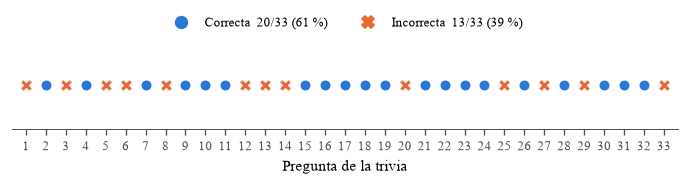

In [4]:
ok = comp["auto"].str.lower().eq("si").values
n_ok = int(ok.sum()); n_tot = len(comp)
fig, ax = plt.subplots(figsize=(COL2, 0.95))
x = comp["n"].values
ax.scatter(x[ok], np.zeros(ok.sum()), marker="o", s=46, color=AZUL, edgecolor="white", lw=0.8, zorder=3)
ax.scatter(x[~ok], np.zeros((~ok).sum()), marker="X", s=52, color=NARANJA, edgecolor="white", lw=0.6, zorder=3)
ax.set_yticks([]); ax.spines["left"].set_visible(False); ax.grid(False)
ax.set_xticks(x); ax.set_xlim(0.3, n_tot + 0.7); ax.set_ylim(-0.3, 0.3)
ax.set_xlabel("Pregunta de la trivia")
ax.legend(handles=[
    Line2D([], [], marker="o", ls="", color=AZUL, ms=7, label=f"Correcta  {n_ok}/{n_tot} ({100*n_ok/n_tot:.0f} %)"),
    Line2D([], [], marker="X", ls="", color=NARANJA, ms=7, label=f"Incorrecta  {n_tot-n_ok}/{n_tot} ({100*(n_tot-n_ok)/n_tot:.0f} %)"),
], loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
guardar(fig, "fig1_veredicto")

## Fig. 2 — Distribución del tiempo de cada módulo (escala logarítmica)

**Qué mide:** el tiempo por turno de cada etapa medida en la Raspberry: capa afectiva (PULSE+ROSE+AEB), LLM, latencia de
respuesta completa, síntesis de voz (TTS) y ventana de captura del FER.

**Por qué esta gráfica — diagrama de caja con los puntos superpuestos, en eje logarítmico:**
- Los módulos abarcan **cinco órdenes de magnitud** (de < 1 ms la capa afectiva a decenas de segundos la ventana FER). En
  escala lineal la capa afectiva y el LLM serían una línea pegada al cero; la escala **log** los hace comparables y
  convierte la pregunta del revisor — "¿cuántas veces más cuesta X que Y?" — en una distancia horizontal.
- La **caja** da mediana y rango intercuartílico (robustos a valores atípicos, que en latencias son comunes); los **puntos** muestran los 33 turnos reales, de modo que no se esconde ni la dispersión ni los atípicos.
- Un solo panel con **un eje compartido** permite ver de un golpe qué módulo domina el tiempo.

**Por qué no otras:**
- *Barras con el promedio:* una barra sólo muestra un número y oculta la variabilidad; además el promedio se sesga con los atípicos (en la capa afectiva, con pocos turnos muy por encima del resto, la media queda lejos de la mediana).
- *Una línea en el tiempo con todos los nodos* (la del notebook anterior): mezclaba un tiempo de cómputo (LLM) con una ventana de captura (FER) en escala lineal, de modo que el FER aplastaba a todo lo demás y el gráfico no permitía leer nada.
- *Violín:* con N = 33 la estimación de densidad inventa forma que los datos no sostienen; los puntos crudos son más honestos.

*Nota:* la capa afectiva se registra con resolución de 0.1 ms; los turnos medidos como 0.0 ms se dibujan en 0.05 ms (< 0.1 ms).

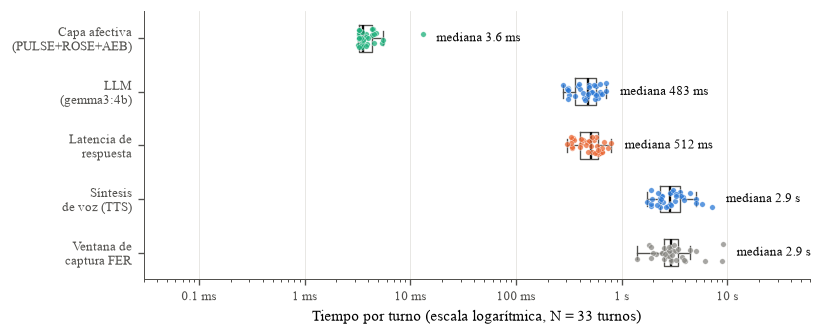

In [5]:
modulos = [   # (etiqueta, serie en ms, color)
    ("Capa afectiva\n(PULSE+ROSE+AEB)", dft["afectiva"].clip(lower=0.05), AQUA),
    ("LLM\n(gemma3:4b)",            dft["LLM"],      AZUL),
    ("Latencia de\nrespuesta",      dft["latencia"], NARANJA),
    ("Síntesis\nde voz (TTS)",      dft["TTS"],      AZUL),
    ("Ventana de\ncaptura FER",     dft["FER"],      GRIS),
]
fig, ax = plt.subplots(figsize=(COL2, 2.9))
rng = np.random.default_rng(7)
for i, (nom, s, c) in enumerate(modulos):
    ax.boxplot(s, positions=[i], orientation="horizontal", widths=0.5, showfliers=False,
               medianprops=dict(color=TINTA, lw=1.4), boxprops=dict(color=TINTA2, lw=0.8),
               whiskerprops=dict(color=TINTA2, lw=0.8), capprops=dict(color=TINTA2, lw=0.8))
    ax.scatter(s, i + rng.uniform(-0.17, 0.17, len(s)), s=11, color=c, alpha=0.75,
               edgecolor="white", lw=0.3, zorder=3)
    med = np.median(s)
    txt = f"{med:.1f} ms" if med < 100 else (f"{med:.0f} ms" if med < 1000 else f"{med/1000:.1f} s")
    ax.text(s.max() * 1.35, i, f"mediana {txt}", va="center", fontsize=8, color=TINTA)
ax.set_xscale("log"); ax.set_xlim(0.03, 6e4)
ax.set_xticks([0.1, 1, 10, 100, 1000, 10000])
ax.set_xticklabels(["0.1 ms", "1 ms", "10 ms", "100 ms", "1 s", "10 s"])
ax.set_yticks(range(len(modulos))); ax.set_yticklabels([m[0] for m in modulos])
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel(f"Tiempo por turno (escala logarítmica, N = {N} turnos)")
guardar(fig, "fig2_tiempos_modulos")

## Fig. 3 — Latencia de respuesta por interacción

**Qué mide:** el tiempo desde que el usuario termina de hablar (fin de la transcripción) hasta que Romeo empieza a
responder, en cada una de las 33 preguntas. Es la métrica que más percibe el usuario.

**Por qué esta gráfica — una sola serie temporal con la mediana y la banda intercuartílica:**
- Responde a "¿la latencia es **estable** a lo largo de la sesión o se degrada?" (calentamiento, temperatura, memoria). Los 33 puntos en orden lo muestran directamente.
- La **distribución** ya está dentro de la misma gráfica: la línea discontinua es la mediana y la franja sombreada contiene la mitad central de los turnos (P25–P75). Los valores mínimo y máximo van anotados, así que el lector obtiene el resumen estadístico completo sin un segundo panel.
- Se marca el umbral de **1 s**, una referencia habitual de respuesta fluida en conversación humano-robot; permite ver de inmediato qué turnos lo superan.

**Por qué no otras:**
- *Agregar una caja (boxplot) al costado* (versión anterior): repetía la mediana y el rango intercuartílico que la banda ya muestra; un segundo panel sin información nueva solo distrae.
- *Solo un histograma:* pierde el orden temporal, y con él la pregunta de la estabilidad.
- *Barras por turno:* 33 barras gruesas dibujan mucha tinta para un dato que es una única serie continua; la línea con marcadores es más limpia.
- *Doble eje con otra métrica:* dos escalas en un mismo gráfico inducen a falsas correlaciones (la posición relativa de las curvas depende de cómo se elija cada eje).

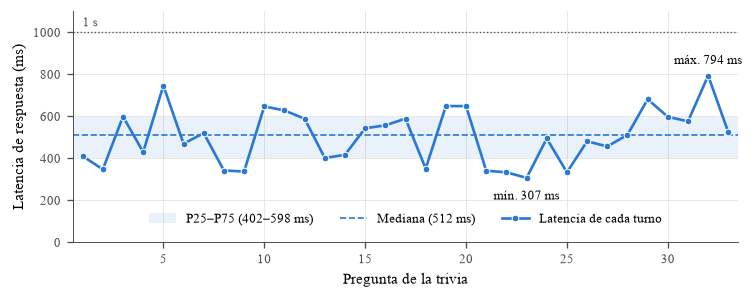

In [6]:
lat = dft["latencia"]; xq = dft["pregunta"]
p25, p50, p75 = np.percentile(lat, [25, 50, 75])
fig, ax = plt.subplots(figsize=(COL2, 2.5))
ax.axhspan(p25, p75, color=AZUL, alpha=0.10, lw=0, label=f"P25–P75 ({p25:.0f}–{p75:.0f} ms)")
ax.axhline(p50, color=AZUL, lw=1, ls="--", label=f"Mediana ({p50:.0f} ms)")
ax.plot(xq, lat, color=AZUL, lw=1.6, marker="o", ms=4, mec="white", mew=0.6, zorder=3,
        label="Latencia de cada turno")
ax.axhline(1000, color=TINTA2, lw=0.8, ls=":")
ax.text(1, 1015, "1 s", va="bottom", fontsize=8, color=TINTA2)
i_min, i_max = lat.idxmin(), lat.idxmax()
ax.annotate(f"mín. {lat[i_min]:.0f} ms", (xq[i_min], lat[i_min]), xytext=(0, -13),
            textcoords="offset points", ha="center", fontsize=7.5, color=TINTA)
ax.annotate(f"máx. {lat[i_max]:.0f} ms", (xq[i_max], lat[i_max]), xytext=(0, 7),
            textcoords="offset points", ha="center", fontsize=7.5, color=TINTA)
ax.set_xlim(0.5, N + 0.5); ax.set_ylim(0, 1100)
ax.set_xlabel("Pregunta de la trivia"); ax.set_ylabel("Latencia de respuesta (ms)")
ax.legend(loc="lower center", ncol=3, bbox_to_anchor=(0.5, 0.02))
guardar(fig, "fig3_latencia")

## Fig. 4 — Composición de la latencia en cada turno

**Qué mide:** de qué está hecha la latencia de la Fig. 3: **LLM**, **capa afectiva** y **resto** (mensajería ROS 2,
parseo y publicación de la respuesta = latencia − LLM − capa afectiva).

**Por qué esta gráfica — barras apiladas por turno:**
- La latencia es una **suma** de etapas; apilar las etapas reproduce esa suma, y la altura total de cada barra coincide con la Fig. 3.
- Hace visible el resultado central para el paper: el LLM ocupa casi toda la barra, y la capa afectiva apenas se distingue (su porcentaje va en la leyenda), lo que respalda que el modelo afectivo no añade un costo apreciable a la interacción. La participación promedio de cada etapa va en la leyenda, así que no hace falta una tabla aparte.
- Un segmento por etapa, con un pequeño espacio entre barras, mantiene legible cada turno.

**Por qué no otras:**
- *Pastel de la composición promedio:* muestra un solo promedio y oculta que la proporción es estable turno a turno (justamente lo que hay que demostrar). Además, una porción de pocos puntos porcentuales no se puede leer en un pastel.
- *Barras agrupadas (una al lado de otra):* compararían etapas entre sí, pero ya no se podría leer el **total**, que es lo que percibe el usuario.
- *Áreas apiladas:* sugieren continuidad entre turnos, que son eventos independientes.

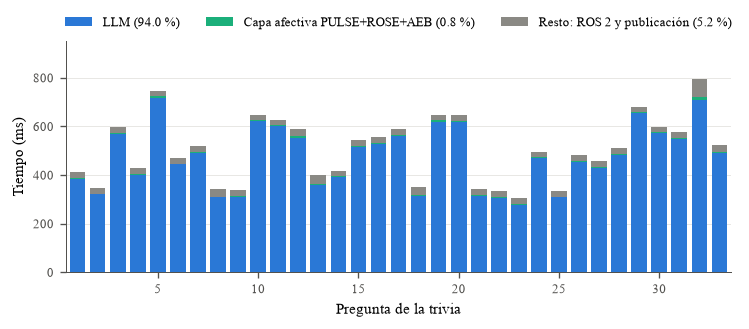

In [7]:
resto = (dft["latencia"] - dft["LLM"] - dft["afectiva"]).clip(lower=0)
tot = dft["latencia"].sum()
pct = lambda s: 100 * s.sum() / tot
fig, ax = plt.subplots(figsize=(COL2, 2.5))
ax.bar(xq, dft["LLM"], width=0.78, color=AZUL, label=f"LLM ({pct(dft['LLM']):.1f} %)", zorder=3)
ax.bar(xq, dft["afectiva"], bottom=dft["LLM"], width=0.78, color=AQUA,
       label=f"Capa afectiva PULSE+ROSE+AEB ({pct(dft['afectiva']):.1f} %)", zorder=3)
ax.bar(xq, resto, bottom=dft["LLM"] + dft["afectiva"], width=0.78, color=GRIS,
       label=f"Resto: ROS 2 y publicación ({pct(resto):.1f} %)", zorder=3)
ax.set_xlim(0.4, N + 0.6); ax.set_ylim(0, 950); ax.grid(axis="x", visible=False)
ax.set_xlabel("Pregunta de la trivia"); ax.set_ylabel("Tiempo (ms)")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
guardar(fig, "fig4_composicion_latencia")

## Fig. 5 — Tiempo del LLM frente a tokens generados

**Qué mide:** cuánto tarda el LLM según la longitud de su respuesta (tokens de salida).

**Por qué esta gráfica — una sola dispersión con recta de regresión e intervalo de confianza del 95 %:**
- La pregunta es una **relación entre dos variables continuas**: la dispersión es la forma canónica. La recta da el costo por token y el costo fijo (la ordenada al origen, que es la latencia de primer token más la red), y la banda del 95 % muestra cuánta confianza merece esa pendiente con N = 33.
- *r* y *r²* cuantifican qué parte de la variación explican los tokens. Si r² es bajo, el costo fijo pesa más que el variable y recortar respuestas ahorraría poco tiempo; si es alto, acortar las respuestas sí reduce la latencia.
- La distribución de longitudes se lee en la propia nube de puntos sobre el eje X; la mediana y el rango de tokens van anotados.

**Por qué no otras:**
- *Agregar un histograma de tokens arriba* (versión anterior): la nube de puntos ya muestra dónde se concentran las longitudes; el panel extra no aportaba un hallazgo nuevo.
- *Histograma y dispersión en figuras separadas:* obliga a cruzar dos ejes X distintos con la vista.
- *Línea por turno:* los tokens no tienen orden temporal relevante para esta pregunta; la línea uniría puntos que no se relacionan.

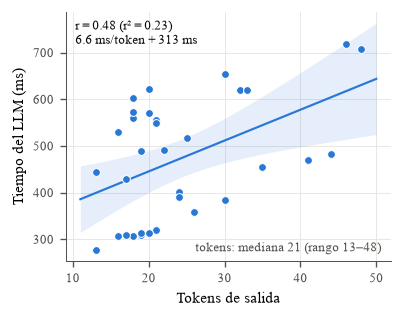

In [8]:
xt = dft["tokens_salida"].values; yt = dft["LLM"].values
b, a = np.polyfit(xt, yt, 1); r = np.corrcoef(xt, yt)[0, 1]
xs = np.linspace(xt.min() - 2, xt.max() + 2, 100)
res = yt - (a + b * xt); s_err = np.sqrt(np.sum(res**2) / (N - 2))
ci = 2.04 * s_err * np.sqrt(1/N + (xs - xt.mean())**2 / np.sum((xt - xt.mean())**2))   # t(0.975, 31) ~ 2.04

fig, ax = plt.subplots(figsize=(COL1, 2.7))
ax.fill_between(xs, a + b*xs - ci, a + b*xs + ci, color=AZUL, alpha=0.12, lw=0)
ax.plot(xs, a + b*xs, color=AZUL, lw=1.3)
ax.scatter(xt, yt, s=22, color=AZUL, edgecolor="white", lw=0.6, zorder=3)
ax.text(0.03, 0.97, f"r = {r:.2f} (r² = {r*r:.2f})\n{b:.1f} ms/token + {a:.0f} ms", transform=ax.transAxes,
        va="top", fontsize=8, color=TINTA)
ax.text(0.97, 0.04, f"tokens: mediana {np.median(xt):.0f} (rango {xt.min():.0f}–{xt.max():.0f})",
        transform=ax.transAxes, ha="right", fontsize=7.5, color=TINTA2)
ax.set_xlabel("Tokens de salida"); ax.set_ylabel("Tiempo del LLM (ms)")
guardar(fig, "fig5_llm_tokens")

## Fig. 6 — Tiempo de síntesis de voz (TTS) frente a la longitud de la frase

**Qué mide:** el tiempo que tarda el servidor TTS en sintetizar las frases de Romeo en los **33 turnos de la trivia**,
en función del número de caracteres. En cada turno Romeo dice dos frases: **hace la pregunta** y luego **evalúa la
respuesta** del usuario; por eso hay 33 de cada una. (Se excluyen la conversación previa a la trivia y los turnos 34 a 37.)

**Por qué esta gráfica — dispersión con regresión, dos series por forma y color:**
- El TTS es la etapa más lenta del turno (Fig. 2), y su costo depende de cuánto texto se sintetiza. La dispersión con la recta da directamente el **costo por carácter**, el dato con el que se puede justificar acortar las respuestas del LLM.
- Pregunta (●) y evaluación (▲) se diferencian por **forma** y color: las evaluaciones las genera el LLM y suelen ser más largas, y la figura permite comprobar si ambas siguen la misma recta, es decir, que la diferencia de tiempo se explica solo por la longitud.
- Usar los mismos 33 turnos que el resto de figuras mantiene el análisis consistente (N = 33).

**Por qué no otras:**
- *Barras con el TTS promedio:* mezcla frases cortas y largas en un solo número que no explica nada.
- *Línea temporal del TTS* (versión anterior, junto al LLM): la variación de turno a turno parecía ruido, cuando en realidad la explica casi por completo la longitud del texto.

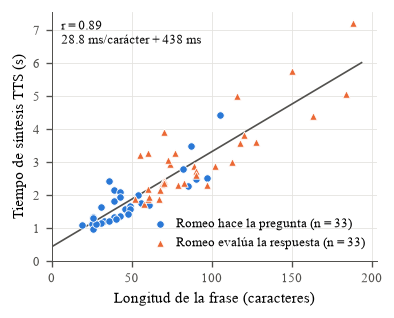

In [9]:
# Solo los 33 turnos: la pregunta que el usuario respondio y la evaluacion de Romeo.
idx_preg = [dtts.index[(dtts["tipo"] == "pregunta") & (dtts["t"] < r["t_mic"])][-1] for r in resp]
idx_eval = [r["idx_tts"] for r in resp]
d33 = pd.concat([dtts.loc[idx_preg].assign(serie="pregunta"),
                 dtts.loc[idx_eval].assign(serie="evaluacion")])
fig, ax = plt.subplots(figsize=(COL1, 2.7))
estilos = {"pregunta": ("o", AZUL, "Romeo hace la pregunta"),
           "evaluacion": ("^", NARANJA, "Romeo evalúa la respuesta")}
for serie, (mk, c, lab) in estilos.items():
    d = d33[d33["serie"] == serie]
    ax.scatter(d["caracteres"], d["t_tts_ms"] / 1000, marker=mk, s=20, color=c,
               edgecolor="white", lw=0.5, label=f"{lab} (n = {len(d)})", zorder=3)
bt, at = np.polyfit(d33["caracteres"], d33["t_tts_ms"], 1)
rt = np.corrcoef(d33["caracteres"], d33["t_tts_ms"])[0, 1]
xs = np.linspace(0, d33["caracteres"].max() * 1.03, 50)
ax.plot(xs, (at + bt * xs) / 1000, color=TINTA2, lw=1)
ax.text(0.03, 0.97, f"r = {rt:.2f}\n{bt:.1f} ms/carácter + {at:.0f} ms", transform=ax.transAxes,
        va="top", fontsize=8, color=TINTA)
ax.set_xlim(0, None); ax.set_ylim(0, None)
ax.set_xlabel("Longitud de la frase (caracteres)"); ax.set_ylabel("Tiempo de síntesis TTS (s)")
ax.legend(loc="lower right", handletextpad=0.2)
guardar(fig, "fig6_tts_longitud")

## Fig. 7 — Recursos de la Raspberry Pi durante la sesión

**Qué mide:** CPU total, CPU del proceso de cámara (FER), temperatura del SoC y RAM usada, cada ~3 s durante toda la
sesión. La zona sombreada es la trivia.

**Por qué esta gráfica — pequeños múltiplos (cuatro paneles con eje X compartido):**
- Son cuatro magnitudes con **unidades distintas** (%, % de un núcleo, °C, GB). Cada una necesita su propio eje Y; apilarlas con el mismo eje de tiempo permite leer qué pasa en todas en un mismo instante sin recurrir a un doble eje.
- La CPU total (porcentaje de los 4 núcleos) y la de la cámara (porcentaje de **un** núcleo, por eso supera el 100 %) tienen **denominadores distintos**: dibujarlas en el mismo panel invitaría a compararlas como si fueran la misma escala.
- La CPU total se muestrea cada ~3 s y oscila mucho entre muestras; se dibuja la serie cruda en trazo tenue y encima la **mediana móvil de 30 s**, que es la tendencia legible. Mostrar ambas evita esconder los picos sin que el ruido tape la tendencia.
- La línea de **80 °C** marca el umbral a partir del cual la Raspberry Pi reduce su frecuencia (*throttling*): muestra cuán cerca del límite opera el sistema. El eje de la RAM parte de 0 para no exagerar variaciones mínimas.

**Por qué no otras:**
- *Doble eje (CPU y temperatura juntas):* el cruce entre curvas depende de cómo se escale cada eje y sugiere correlaciones que no existen.
- *Barras o valores promedio:* ocultan los picos y el calentamiento progresivo, que son lo que importa para evaluar si el sistema es sostenible en sesiones largas.

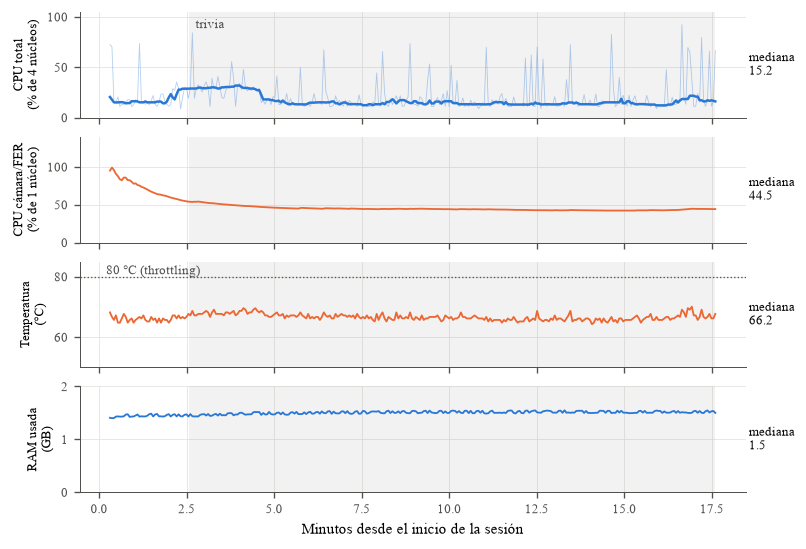

In [10]:
m0 = (INICIO_TRIVIA - T_INICIO_SESION) / 60; m1 = sis["min"].max()
ram_gb = sis["ram_usada_mb"] / 1024
paneles = [
    ("CPU total\n(% de 4 núcleos)", sis["cpu_total_pct"], AZUL, (0, 105), None),
    ("CPU cámara/FER\n(% de 1 núcleo)", sis["cpu_camara_pct"], NARANJA, (0, 140), None),
    ("Temperatura\n(°C)", sis["temp_c"], NARANJA, (50, 85), 80),
    ("RAM usada\n(GB)", ram_gb, AZUL, (0, np.ceil(ram_gb.max() * 1.25 * 2) / 2), None),
]
fig, axs = plt.subplots(4, 1, figsize=(COL2, 5.2), sharex=True, gridspec_kw=dict(hspace=0.18))
for k, (ax, (lab, s, c, yl, umbral)) in enumerate(zip(axs, paneles)):
    ax.axvspan(m0, m1, color=GRIS, alpha=0.10, lw=0)
    if k == 0:   # CPU total: cruda tenue + mediana movil de 30 s (10 muestras)
        ax.plot(sis["min"], s, color=c, lw=0.5, alpha=0.35)
        ax.plot(sis["min"], s.rolling(10, center=True, min_periods=3).median(), color=c, lw=1.5)
    else:
        ax.plot(sis["min"], s, color=c, lw=1.1)
    ax.set_ylabel(lab, fontsize=8); ax.set_ylim(*yl)
    ax.text(1.005, 0.5, f"mediana\n{s.median():.1f}", transform=ax.transAxes, fontsize=7.5,
            va="center", color=TINTA)
    if umbral:
        ax.axhline(umbral, color=TINTA2, lw=0.8, ls=":")
        ax.text(0.2, umbral + 0.8, f"{umbral} °C (throttling)", fontsize=7.5, color=TINTA2)
axs[0].text(m0 + 0.2, 98, "trivia", fontsize=8, color=TINTA2, va="top")
axs[-1].set_xlabel("Minutos desde el inicio de la sesión")
guardar(fig, "fig7_recursos_pi")